# Synthea FHIR Data Analysis Notebook
This notebook provides a basic framework for processing and analyzing FHIR JSON data generated by Synthea. It demonstrates how to read the FHIR Bundles, extract key information from various resource types (Patient, Condition, MedicationRequest, Observation, Procedure), and store it in Pandas DataFrames for further analysis and visualization.

In [5]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Configuration ---
# Path to your Synthea output directory containing FHIR JSON files
FHIR_OUTPUT_DIR = os.environ.get('SYNTHEA_FHIR_DIR', 'data/synthea/output/fhir')

# --- Data Extraction Functions ---
def extract_patient_data(resource):
    """Extracts key demographic information from a FHIR Patient resource."""
    patient_id = resource.get('id')
    gender = resource.get('gender')
    birth_date = resource.get('birthDate')
    # Extract extensions for race and ethnicity if present
    race = None
    ethnicity = None
    for ext in resource.get('extension', []):
        if 'url' in ext and 'valueCoding' in ext:
            if 'ombCategory' in ext['url'] and ext['url'].endswith('race'):
                race = ext['valueCoding'].get('display')
            elif 'ombCategory' in ext['url'] and ext['url'].endswith('ethnicity'):
                ethnicity = ext['valueCoding'].get('display')
    return {'patient_id': patient_id, 'gender': gender, 'birth_date': birth_date, 'race': race, 'ethnicity': ethnicity}

def extract_condition_data(resource, patient_id):
    """Extracts key information from a FHIR Condition resource."""
    condition_id = resource.get('id')
    code = resource.get('code', {}).get('coding', [{}])[0].get('display')
    onset_date = resource.get('onsetDateTime')
    recorded_date = resource.get('recordedDate')
    clinical_status = resource.get('clinicalStatus', {}).get('coding', [{}])[0].get('code')
    return {'patient_id': patient_id, 'condition_id': condition_id, 'code': code, 'onset_date': onset_date, 'recorded_date': recorded_date, 'clinical_status': clinical_status}

def extract_medication_data(resource, patient_id):
    """Extracts key information from a FHIR MedicationRequest resource."""
    medication_id = resource.get('id')
    medication_name = resource.get('medicationCodeableConcept', {}).get('coding', [{}])[0].get('display')
    authored_on = resource.get('authoredOn')
    return {'patient_id': patient_id, 'medication_id': medication_id, 'medication_name': medication_name, 'authored_on': authored_on}

def extract_observation_data(resource, patient_id):
    """Extracts key information from a FHIR Observation resource."""
    observation_id = resource.get('id')
    code = resource.get('code', {}).get('coding', [{}])[0].get('display')
    value = resource.get('valueQuantity', {}).get('value')
    unit = resource.get('valueQuantity', {}).get('unit')
    effective_date = resource.get('effectiveDateTime')
    return {'patient_id': patient_id, 'observation_id': observation_id, 'code': code, 'value': value, 'unit': unit, 'effective_date': effective_date}

def extract_procedure_data(resource, patient_id):
    """Extracts key information from a FHIR Procedure resource."""
    procedure_id = resource.get('id')
    code = resource.get('code', {}).get('coding', [{}])[0].get('display')
    performed_date = resource.get('performedDateTime')
    return {'patient_id': patient_id, 'procedure_id': procedure_id, 'code': code, 'performed_date': performed_date}

# --- Main Processing Logic ---
all_patients_data = []
all_conditions_data = []
all_medications_data = []
all_observations_data = []
all_procedures_data = []

fhir_files = [f for f in os.listdir(FHIR_OUTPUT_DIR) if f.endswith('.json')]
print(f"Found {len(fhir_files)} FHIR JSON files in {FHIR_OUTPUT_DIR}")

for fhir_file in fhir_files:
    file_path = os.path.join(FHIR_OUTPUT_DIR, fhir_file)
    try:
        with open(file_path, 'r', encoding='utf-8') as f:
            bundle = json.load(f)

        # Assuming the first resource in the bundle's entry is always the Patient resource for simplicity
        # In a more robust solution, you would iterate and find the Patient resource explicitly.
        patient_resource = None
        for entry in bundle.get('entry', []):
            resource = entry.get('resource')
            if resource and resource.get('resourceType') == 'Patient':
                patient_resource = resource
                break
        
        if patient_resource:
            patient_data = extract_patient_data(patient_resource)
            all_patients_data.append(patient_data)
            current_patient_id = patient_data['patient_id']

            for entry in bundle.get('entry', []):
                resource = entry.get('resource')
                if resource:
                    if resource.get('resourceType') == 'Condition':
                        all_conditions_data.append(extract_condition_data(resource, current_patient_id))
                    elif resource.get('resourceType') == 'MedicationRequest':
                        all_medications_data.append(extract_medication_data(resource, current_patient_id))
                    elif resource.get('resourceType') == 'Observation':
                        all_observations_data.append(extract_observation_data(resource, current_patient_id))
                    elif resource.get('resourceType') == 'Procedure':
                        all_procedures_data.append(extract_procedure_data(resource, current_patient_id))
        else:
            print(f"Warning: No Patient resource found in {fhir_file}")

    except json.JSONDecodeError:
        print(f"Error: Could not decode JSON from {fhir_file}")
    except Exception as e:
        print(f"An unexpected error occurred while processing {fhir_file}: {e}")

# Convert lists of dictionaries to Pandas DataFrames
df_patients = pd.DataFrame(all_patients_data)
df_conditions = pd.DataFrame(all_conditions_data)
df_medications = pd.DataFrame(all_medications_data)
df_observations = pd.DataFrame(all_observations_data)
df_procedures = pd.DataFrame(all_procedures_data)

print("\n--- DataFrames Created ---")
print(f"Patients DataFrame shape: {df_patients.shape}")
print(f"Conditions DataFrame shape: {df_conditions.shape}")
print(f"Medications DataFrame shape: {df_medications.shape}")
print(f"Observations DataFrame shape: {df_observations.shape}")
print(f"Procedures DataFrame shape: {df_procedures.shape}")

Found 74 FHIR JSON files in output/fhir

--- DataFrames Created ---
Patients DataFrame shape: (70, 5)
Conditions DataFrame shape: (2232, 6)
Medications DataFrame shape: (2247, 4)
Observations DataFrame shape: (25323, 6)
Procedures DataFrame shape: (10251, 4)


## Basic Analysis and Visualizations
Now that the data is in DataFrames, you can perform various analyses. Here are some examples.


--- Patient Gender Distribution ---
gender
female    38
male      32
Name: count, dtype: int64


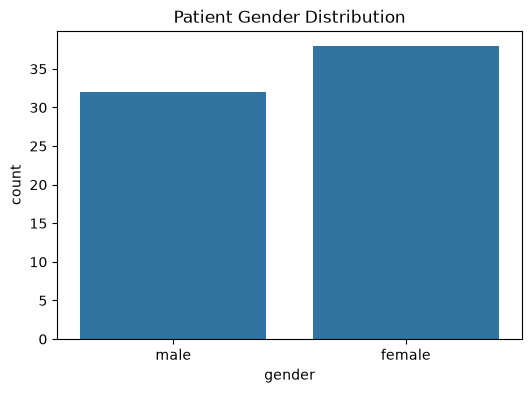

In [6]:
# Example 1: Patient Gender Distribution
if not df_patients.empty:
    print("\n--- Patient Gender Distribution ---")
    print(df_patients['gender'].value_counts())
    plt.figure(figsize=(6, 4))
    sns.countplot(x='gender', data=df_patients)
    plt.title('Patient Gender Distribution')
    plt.show()
else:
    print("No patient data to analyze for gender distribution.")


--- Top 10 Conditions ---
code
Medication review due (situation)     456
Stress (finding)                      166
Full-time employment (finding)        147
Gingivitis (disorder)                 147
Part-time employment (finding)         95
Viral sinusitis (disorder)             76
Not in labor force (finding)           62
Limited social contact (finding)       57
Social isolation (finding)             56
Acute viral pharyngitis (disorder)     48
Name: count, dtype: int64


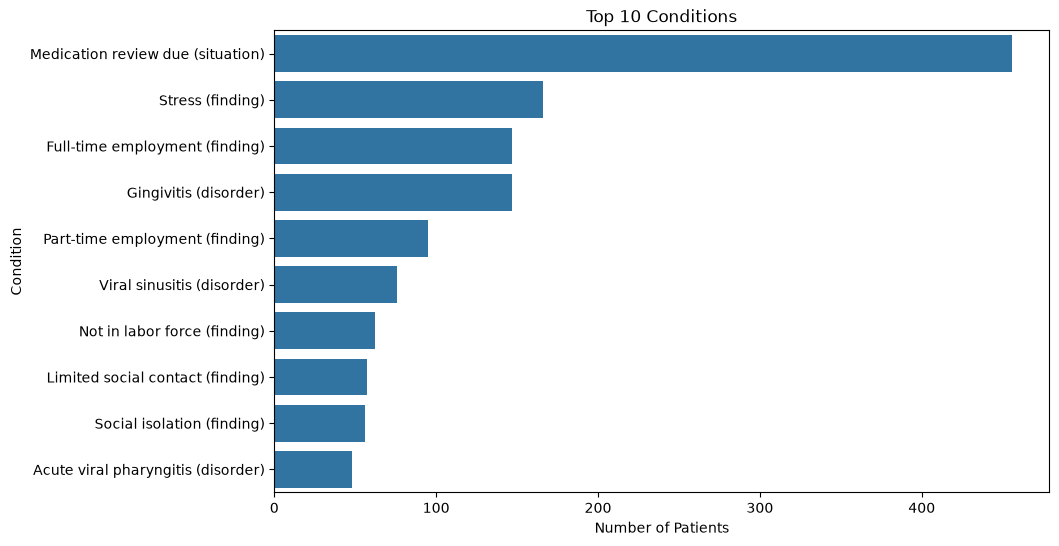

In [7]:
# Example 2: Top 10 Conditions
if not df_conditions.empty:
    print("\n--- Top 10 Conditions ---")
    top_conditions = df_conditions['code'].value_counts().head(10)
    print(top_conditions)
    plt.figure(figsize=(10, 6))
    sns.barplot(x=top_conditions.values, y=top_conditions.index)
    plt.title('Top 10 Conditions')
    plt.xlabel('Number of Patients')
    plt.ylabel('Condition')
    plt.show()
else:
    print("No condition data to analyze for top conditions.")


--- Patient Age Distribution ---


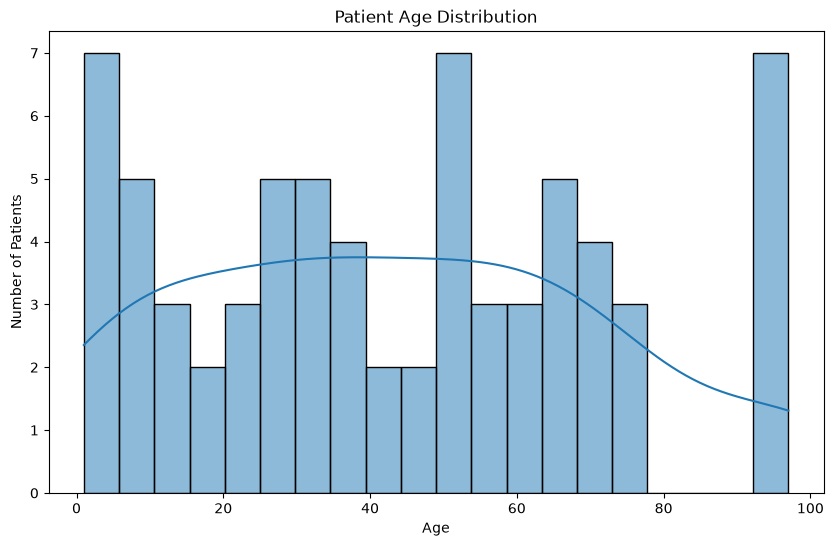

In [8]:
# Example 3: Patient Age Distribution (requires parsing birth_date)
if not df_patients.empty:
    df_patients['birth_date'] = pd.to_datetime(df_patients['birth_date'])
    # Assuming current date is today for age calculation, adjust as needed
    current_date = pd.to_datetime('2026-09-15') # Using today's date from environment
    df_patients['age'] = (current_date - df_patients['birth_date']).dt.days // 365

    print("\n--- Patient Age Distribution ---")
    plt.figure(figsize=(10, 6))
    sns.histplot(df_patients['age'].dropna(), bins=20, kde=True)
    plt.title('Patient Age Distribution')
    plt.xlabel('Age')
    plt.ylabel('Number of Patients')
    plt.show()
else:
    print("No patient data to analyze for age distribution.")


--- Patient Age Distribution ---


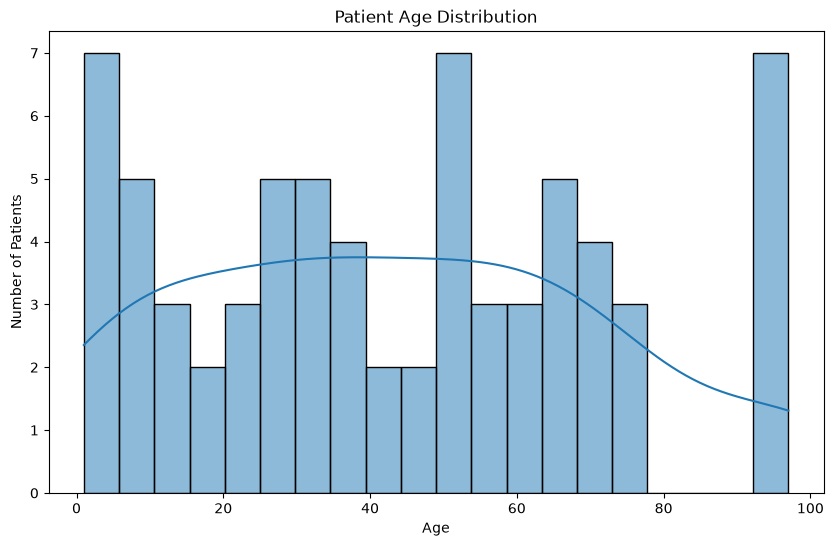

In [9]:
# Example 3: Patient Age Distribution (requires parsing birth_date)
if not df_patients.empty:
    df_patients['birth_date'] = pd.to_datetime(df_patients['birth_date'])
    # Assuming current date is today for age calculation, adjust as needed
    current_date = pd.to_datetime('2026-09-15') # Using today's date from environment
    df_patients['age'] = (current_date - df_patients['birth_date']).dt.days // 365

    print("\n--- Patient Age Distribution ---")
    plt.figure(figsize=(10, 6))
    sns.histplot(df_patients['age'].dropna(), bins=20, kde=True)
    plt.title('Patient Age Distribution')
    plt.xlabel('Age')
    plt.ylabel('Number of Patients')
    plt.show()
else:
    print("No patient data to analyze for age distribution.")